# Classifying Power Consumption into 3 Energy States (K-Means)

**Goal:** learn unsupervised learning by grouping household power readings into three energy states, **without ever giving the model labels**.

**Why unsupervised?** In supervised learning we'd tell the model "this reading is standby, this one is heavy". Here the model only sees raw numbers and has to discover the groups by itself, based on which readings look similar.

---
## Step 1: Generate the dataset

Real smart-meter data isn't available, so this cell **simulates** two weeks of hourly readings (14 days × 24 hours = 336 rows).

**Each row has 3 features:**
| Feature | Meaning | Unit |
|---|---|---|
| `Active_Power` | Power actually being consumed | kW |
| `Voltage` | Supply voltage (sags slightly under heavy load) | V |
| `Current` | Current drawn | A |

**How the data is built:**
- Every day follows a realistic cycle: **8 h standby (night) → 10 h normal use (day) → 6 h heavy load (evening peak)**.
- Each state is drawn from a **normal (Gaussian) distribution** with its own mean and spread, using `np.random.normal`. This adds natural noise so the states overlap a little, like real data.
- `np.random.seed(42)` makes the random numbers repeatable, so you get the same data every run.

**Output:** the data is saved to `real_life_energy_data.csv` and the first 10 rows are printed.


In [4]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# 1. Create a realistic timestamp index (hourly readings over 14 days = 336 rows)
timestamps = pd.date_range(
    start="2026-10-01 00:00:00", periods=336, freq="h"
)

# 2. Simulate realistic operating states with natural variations and noise
# Standby (e.g., nights): Low power (~0.2 kW), stable voltage, low current
standby = np.random.normal(loc=[0.25, 230.5, 1.1], scale=[0.08, 1.5, 0.2], size=(120, 3))

# Normal use (e.g., daytime): Moderate power (~1.5 kW), slight voltage drop, medium current
normal = np.random.normal(loc=[1.60, 228.2, 7.0], scale=[0.35, 2.5, 0.8], size=(144, 3))

# Heavy load (e.g., evening peak / heavy appliances): High power (~4.5 kW), voltage sag, high current
heavy = np.random.normal(loc=[4.40, 224.8, 19.2], scale=[0.60, 3.8, 1.5], size=(72, 3))

# Combine and shuffle slightly to mimic natural chronological transitions
raw_data = np.vstack([standby, normal, heavy])
# Shuffle row order slightly while maintaining realism, or keep chronological order
# Let's create a realistic daily cycle by sorting or arranging them sequentially:
# Night -> Day -> Evening pattern repeated
energy_matrix = []
for day in range(14):
    # Each day: 8 hours standby, 10 hours normal, 6 hours heavy
    day_data = np.vstack([
        np.random.normal(loc=[0.22, 230.8, 0.9], scale=[0.05, 1.0, 0.1], size=(8, 3)),
        np.random.normal(loc=[1.50, 228.5, 6.5], scale=[0.25, 2.0, 0.5], size=(10, 3)),
        np.random.normal(loc=[4.30, 225.0, 18.8], scale=[0.45, 3.0, 1.1], size=(6, 3))
    ])
    energy_matrix.append(day_data)

final_data = np.vstack(energy_matrix)

# 3. Build the final DataFrame
df = pd.DataFrame(final_data, columns=['Active_Power', 'Voltage', 'Current'])
df.insert(0, 'Timestamp', timestamps)

# Round values for clean real-world precision
df['Active_Power'] = df['Active_Power'].round(3)
df['Voltage'] = df['Voltage'].round(1)
df['Current'] = df['Current'].round(2)

# 4. Save to CSV
df.to_csv('real_life_energy_data.csv', index=False)

print("real_life_energy_data.csv generated successfully!")
print(df.head(10))

real_life_energy_data.csv generated successfully!
            Timestamp  Active_Power  Voltage  Current
0 2026-10-01 00:00:00         0.272    230.3     1.03
1 2026-10-01 01:00:00         0.230    232.9     0.83
2 2026-10-01 02:00:00         0.307    231.0     0.83
3 2026-10-01 03:00:00         0.196    230.5     0.94
4 2026-10-01 04:00:00         0.246    230.2     0.90
5 2026-10-01 05:00:00         0.327    232.5     0.94
6 2026-10-01 06:00:00         0.222    230.9     0.96
7 2026-10-01 07:00:00         0.169    230.5     0.73
8 2026-10-01 08:00:00         1.600    229.8     6.26
9 2026-10-01 09:00:00         1.893    226.0     5.77


## Step 2: Train K-Means and inspect the clusters

This cell is the core of the project. It does five things:

**1. Load data & pick features**
Reads the CSV and selects `Active_Power`, `Voltage` and `Current` as `X`. The timestamp is left out because it isn't a measurement of the energy state.

**2. Scale the features** (`StandardScaler`)
K-Means works on **distances**. Voltage is around ~230 while power is ~0.2–5, so without scaling, voltage would dominate the distance calculation and the other features would barely matter. Scaling converts each feature to mean 0 and standard deviation 1 so they contribute equally.

**3. Train K-Means**
- `n_clusters=3`: we want 3 energy states.
- `init='k-means++'`: smart starting centroids that are spread apart, which gives more stable results than random starts.
- `n_init=10`: runs the algorithm 10 times with different starts and keeps the best one.
- `random_state=42`: reproducibility.

**4. Assign each reading to a state**
The cluster number (0, 1 or 2) is stored in a new `Energy state` column. The centroids (cluster centers) are kept in `cluster_centroids`.

**5. Evaluate**
- **Silhouette score** (range −1 to 1) measures how well each point fits its own cluster compared to the nearest other cluster. Higher is better. Our score of **~0.57** means the clusters are reasonably well separated.
- The **group-by average table** shows what each cluster *means* in real units:

| Cluster | Avg Power | Avg Voltage | Avg Current | Interpretation |
|---|---|---|---|---|
| 0 | ~0.34 kW | ~230.9 V | ~1.5 A | **Standby** |
| 2 | ~1.56 kW | ~228.3 V | ~6.5 A | **Normal use** |
| 1 | ~4.30 kW | ~225.1 V | ~18.7 A | **Heavy load** |

**6. Visualise**
Scatter plot of Power vs Current, coloured by cluster, with the centroids marked as red ✖. Centroids are converted back to original units with `inverse_transform` so they line up with the unscaled axes.



silhouette score: 0.5705369038694181
cluster profile average
              Active_Power     Voltage    Current
Energy state                                     
0                 0.342089  230.904032   1.452903
1                 4.300667  225.071429  18.690357
2                 1.559523  228.258594   6.521172


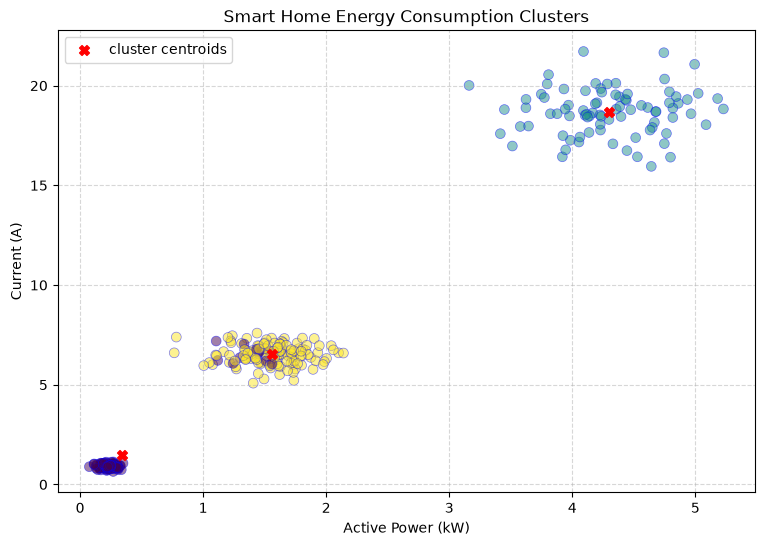

In [5]:
#importing libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,mean_squared_error
from sklearn.preprocessing import StandardScaler

#loading the file using pandas
df=pd.read_csv('real_life_energy_data.csv')

#preparing features
X=df[["Active_Power","Voltage","Current"]]

#feature sclaling a must
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

#creating and Training Model
model=KMeans(n_clusters=3,init='k-means++',n_init=10,random_state=42)
model.fit(X_scaled)

#predictions
df["Energy state"]=model.predict(X_scaled)
cluster_centroids=model.cluster_centers_

#checking for accuracy
print("silhouette score:",silhouette_score(X_scaled,df["Energy state"]))
print("cluster profile average")
# Calculate mean only on numerical columns
print(df.groupby("Energy state").mean(numeric_only=True))

#visualizations
original_centroids=scaler.inverse_transform(model.cluster_centers_)
#plotting the data points
plt.figure(figsize=(9,6))

#scatter plot of the data points
plt.scatter(
    df["Active_Power"],
    df["Current"],
    c=df["Energy state"],
    cmap="viridis",
    s=50,
    alpha=0.5,
    edgecolors="b",
    linewidth=0.5

)

#scatter plot of the centroids
plt.scatter(
    original_centroids[:,0],
     original_centroids[:,2],
    c="red",
    s=50,
    marker="X",
    label="cluster centroids"

)

# Add titles, labels, and layout styling
plt.title("Smart Home Energy Consumption Clusters")
plt.xlabel("Active Power (kW)")
plt.ylabel("Current (A)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Show the finished plot
plt.show()


## Step 3: Test the trained model on new readings

Now we use the model like it would be used in real life: give it **brand-new readings** and ask which energy state they belong to.

**What the cell does:**
1. **Loads** the saved model and scaler with `joblib`. (`energy_kmeans_model.pkl`, `energy_scaler.pkl`)
2. Defines one hand-made reading per state, in the order `[Active_Power, Voltage, Current]`:
   - Standby: `[0.25, 230.0, 0.9]`
   - Normal: `[1.55, 228.2, 6.8]`
   - Heavy: `[4.45, 224.5, 19.1]`
3. **Scales each reading with the *same* scaler used in training**. This is critical: new data must be transformed with the training mean/std (`transform`, never `fit_transform`), otherwise the model sees values on a different scale.
4. Calls `model.predict()`, which assigns the reading to the **nearest centroid**.

**Result:** the three readings land in three different clusters: Standby → **0**, Normal → **2**, Heavy → **1**. This matches the cluster profiles from Step 2, so the model generalises to unseen inputs.

> - The `UserWarning` about feature names is harmless. The scaler was trained on a DataFrame (with column names) but receives plain lists here. To silence it, pass a DataFrame: `pd.DataFrame(reading, columns=["Active_Power","Voltage","Current"])`.
> - Cluster IDs (0/1/2) are only meaningful for this trained model. To make output readable, map them: `{0: "Standby", 2: "Normal", 1: "Heavy"}`.

---
### 🎓 Key takeaways
1. Unsupervised learning finds structure in **unlabelled** data.
2. **Scale** your features before distance-based algorithms like K-Means.
3. **You** interpret the clusters. The algorithm only groups, it doesn't name.
4. Reuse the **same scaler** for new data, and **save both** model and scaler together.

In [8]:
import joblib

# 1. Load the saved model and scaler
model = joblib.load('energy_kmeans_model.pkl')
scaler = joblib.load('energy_scaler.pkl')

# 2. Define custom readings for all 3 states: [Active_Power, Voltage, Current]
reading_standby = [[0.25, 230.0, 0.9]]
reading_normal = [[1.55, 228.2, 6.8]]
reading_heavy = [[4.45, 224.5, 19.1]]

# 3. Scale and predict for Standby
scaled_standby = scaler.transform(reading_standby)
cluster_standby = model.predict(scaled_standby)

# 4. Scale and predict for Normal
scaled_normal = scaler.transform(reading_normal)
cluster_normal = model.predict(scaled_normal)

# 5. Scale and predict for Heavy Load
scaled_heavy = scaler.transform(reading_heavy)
cluster_heavy = model.predict(scaled_heavy)

# 6. Show the results for all three
print("--- Testing All Three Energy States ---")
print("Standby Reading:", reading_standby, "--> Predicted Cluster:", cluster_standby)
print("Normal Reading:", reading_normal, "--> Predicted Cluster:", cluster_normal)
print("Heavy Reading:", reading_heavy, "--> Predicted Cluster:", cluster_heavy)

--- Testing All Three Energy States ---
Standby Reading: [[0.25, 230.0, 0.9]] --> Predicted Cluster: [0]
Normal Reading: [[1.55, 228.2, 6.8]] --> Predicted Cluster: [2]
Heavy Reading: [[4.45, 224.5, 19.1]] --> Predicted Cluster: [1]


c:\Users\User\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
